# BudgetPilot — Ad Budget Optimization Agent
**BUS4-118S Sec 02 · Group Exercise: Agentic AI in Marketing**
**Group:** Anagha Ayyagari, Shayan, Arshdeep

A minimal agent that splits a fixed **$1,500/day** budget across **Search, Social and Display** to **maximize conversions**.
Each morning it: **reads** yesterday's performance → **computes** CTR / CVR / CPA → **proposes** a budget shift toward the best channel → **applies guardrails** → **logs** a reason for every change.
We evaluate it against an **equal-split baseline** on 28 days of mock data.

## 1. Load the data
`data/ad_performance.csv` — 28 days × 3 channels, columns `date, channel, spend, impressions, clicks, conversions` (generated by `data/generate_mock_data.py`; the history is an equal $500/channel/day split).

In [1]:
import json
import pandas as pd

try:
    from IPython.display import Image, display
except ImportError:  # running outside Jupyter
    Image = display = print

from agent import (AgentConfig, BudgetAgent, EqualSplitBaseline, GreedyNoGuardrails, SYSTEM_PROMPT_PATH,
                   apply_guardrails, compute_metrics, load_performance_csv, propose_budget, read_performance)
from simulator import MarketSimulator
from run_evaluation import run_policy, summarize, robustness, sensitivity, plot_budget_allocation, plot_cumulative

data = load_performance_csv("data/ad_performance.csv")   # also runs the privacy check
print(f"{len(data)} rows | {data['date'].min():%b %d} to {data['date'].max():%b %d, %Y} | channels: {sorted(data['channel'].unique())}")
data.head(6)

84 rows | Sep 28 to Oct 25, 2026 | channels: ['Display', 'Search', 'Social']


,date,channel,spend,impressions,clicks,conversions
0,2026-09-28,Display,500.0,171315,466,7
1,2026-09-28,Search,500.0,7801,216,10
2,2026-09-28,Social,500.0,51932,446,10
3,2026-09-29,Display,500.0,169871,383,3
4,2026-09-29,Search,500.0,7244,237,22
5,2026-09-29,Social,500.0,56135,474,12


In [2]:
# Historical performance by channel (equal split) — CTR, CVR, CPA
hist = data.groupby("channel")[["spend", "impressions", "clicks", "conversions"]].sum()
hist["CTR %"] = (hist.clicks / hist.impressions * 100).round(2)
hist["CVR %"] = (hist.conversions / hist.clicks * 100).round(2)
hist["CPA $"] = (hist.spend / hist.conversions).round(2)
hist

,spend,impressions,clicks,conversions,CTR %,CVR %,CPA $
channel,,,,,,,
Display,14000.0,4668165,11749,163,0.25,1.39,85.89
Search,14000.0,204028,6137,429,3.01,6.99,32.63
Social,14000.0,1549948,15698,504,1.01,3.21,27.78


## 2. System prompt
The agent's role, tools, decision rules and hard guardrails. The rule-based policy implements exactly these rules; the optional LLM advisor (`--llm`) receives this prompt verbatim.

In [3]:
print(SYSTEM_PROMPT_PATH.read_text())

# System Prompt — Ad Budget Optimization Agent

You are **BudgetPilot**, a cautious marketing-operations agent. Each morning you
decide how to split a fixed daily ad budget across three channels
(Search, Social, Display) to **maximize conversions** at a healthy cost per
acquisition (CPA).

## Your tools
- `read_performance(day)` — returns channel-level spend, impressions, clicks and
  conversions for every day *before* `day`. Aggregate data only.
- `compute_metrics(history)` — returns recency-weighted CTR, CVR, CPA and
  conversions-per-dollar for each channel.
- `propose_budget(metrics, current_budget)` — suggests which channel to grow,
  which to shrink, and by how much (10–20 % of the winner's budget).
- `apply_guardrails(proposal, current_budget)` — enforces the hard limits below.
  Its output is final; you may not override it.
- `log_decision(...)` — records the budgets and a one-line reason per channel.

## How to decide
1. Start with an equal split. Hold it for a 2-day warm-up s

## 3. The tools, step by step (example: the morning of day 8)

In [4]:
config = AgentConfig()                       # $1,500/day, +/-20%/day, 10% floor, 60% cap
day8 = sorted(data["date"].unique())[7]
known = read_performance(data, day8)         # tool 1: only data BEFORE day 8 (no peeking)
metrics = compute_metrics(known, config)     # tool 2: recency-weighted CTR/CVR/CPA, last 7 days
print(f"Portfolio CPA: ${metrics.attrs['portfolio_cpa']:.2f}")
metrics[["ctr", "cvr", "cpa", "conv_per_dollar"]].round(4)

Portfolio CPA: $39.34


,ctr,cvr,cpa,conv_per_dollar
Display,0.0025,0.0157,75.3075,0.0133
Search,0.0303,0.0804,28.6663,0.0349
Social,0.0093,0.0286,35.5851,0.0281


In [5]:
current = {"Search": 500, "Social": 500, "Display": 500}
proposal = propose_budget(metrics, current, config)          # tool 3: explore/exploit heuristic
new_budget, notes = apply_guardrails(proposal, current, config)  # tool 4: hard limits, final say
print("Proposal :", proposal.action, "->", proposal.increase, f"+{proposal.shift_pct:.0%}",
      f"(CPA edge vs portfolio {proposal.edge:.0%}), funded by", proposal.donors)
print("Budget   :", current, "->", new_budget)
print("Guardrail notes:", notes or "none")

Proposal : shift -> Search +20% (CPA edge vs portfolio 27%), funded by ['Display', 'Social']
Budget   : {'Search': 500, 'Social': 500, 'Display': 500} -> {'Search': 600, 'Social': 500, 'Display': 400}
Guardrail notes: none


## 4. Run the agent for 28 days (and the baseline)
The simulator replays each day using that day's observed CPM, CTR and CVR, with **diminishing returns** when a channel gets more than its historical spend (elasticity 0.35). All policies face the same simulated market and random seed.

In [6]:
sim = MarketSimulator(data, elasticity=0.35, seed=42)
agent = BudgetAgent(config)
policies = [agent, EqualSplitBaseline(config.daily_budget), GreedyNoGuardrails(config.daily_budget)]
results = pd.concat([run_policy(p, sim) for p in policies], ignore_index=True)
log = pd.DataFrame(agent.log)
log.to_csv("outputs/decision_log.csv", index=False)
print(f"Agent made {log.groupby('day').action.first().eq('shift').sum()} budget shifts over {log.day.nunique()} days")

Agent made 10 budget shifts over 28 days


In [7]:
# Decision log — one reason string per channel per day (first week of decisions)
for _, r in log[(log.day >= 3) & (log.day <= 6)].iterrows():
    print(f"Day {r.day:>2}  {r.reason}")

Day  3  Search up 20% ($500->$600) due to better CPA $28.08 vs $47.33 portfolio (41% better), CVR 7.2%, stable CPA
Day  3  Social held at $500 (CPA $55.56): not the best or worst performer
Day  3  Display down 20% ($500->$400) due to higher CPA $102.35; budget moved to Search
Day  4  Search up 20% ($600->$720) due to better CPA $25.55 vs $39.47 portfolio (35% better), CVR 8.7%, stable CPA
Day  4  Social down 8% ($500->$460) due to higher CPA $48.84; budget moved to Search
Day  4  Display down 20% ($400->$320) due to higher CPA $69.69; budget moved to Search [limited by guardrail (-20%/day or 10% floor)]
Day  5  Search up 20% ($720->$864) due to better CPA $25.62 vs $39.83 portfolio (36% better), CVR 8.7%, stable CPA
Day  5  Social down 17% ($460->$380) due to higher CPA $60.01; budget moved to Search
Day  5  Display down 20% ($320->$256) due to higher CPA $68.08; budget moved to Search [limited by guardrail (-20%/day or 10% floor)]
Day  6  Search up 4% ($864->$900) due to better CPA $3

In [8]:
# Around the Social creative refresh (day 15) the agent notices and moves budget
for _, r in log[(log.day >= 15) & (log.day <= 17)].iterrows():
    print(f"Day {r.day:>2}  {r.reason}")

Day 15  Search held at $900 (CPA $35.88): at 60% max share
Day 15  Social up 10% ($380->$418) due to better CPA $36.42 vs $39.76 portfolio (8% better), CVR 2.5%, stable CPA
Day 15  Display down 17% ($220->$182) due to higher CPA $99.81; budget moved to Social
Day 16  Search down 6% ($900->$849) due to higher CPA $41.23; budget moved to Social
Day 16  Social up 20% ($418->$501) due to better CPA $27.95 vs $38.49 portfolio (27% better), CVR 3.2%, stable CPA
Day 16  Display down 18% ($182->$150) due to higher CPA $65.87; budget moved to Social; kept at 10% floor to keep learning [limited by guardrail (-20%/day or 10% floor)]
Day 17  Search down 12% ($849->$749) due to higher CPA $40.36; budget moved to Social
Day 17  Social up 20% ($501->$601) due to better CPA $26.50 vs $36.69 portfolio (28% better), CVR 3.4%, stable CPA
Day 17  Display held at $150 (CPA $62.63): at 10% floor, kept for learning [limited by guardrail (-20%/day or 10% floor)]


In [9]:
# Daily budgets chosen by the agent
log.pivot(index="day", columns="channel", values="budget_after")[["Search", "Social", "Display"]].T

day,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28
channel,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Search,500,500,600,720,864,900,900,900,900,900,900,900,900,900,900,849,749,629,504,450,450,450,450,450,450,450,450,450
Social,500,500,500,460,380,380,380,380,380,380,380,380,380,380,418,501,601,721,846,900,900,900,900,900,900,900,900,900
Display,500,500,400,320,256,220,220,220,220,220,220,220,220,220,182,150,150,150,150,150,150,150,150,150,150,150,150,150


## 5. Evaluation vs. equal-split baseline

In [10]:
summary = pd.DataFrame({p.name: summarize(results[results.policy == p.name]) for p in policies}).T
base, ag = summary.loc["Equal-split baseline"], summary.loc["BudgetPilot agent"]
print(f"Conversions: {ag.conversions:,.0f} vs {base.conversions:,.0f} baseline "
      f"-> {(ag.conversions / base.conversions - 1):+.1%} ({ag.conversions - base.conversions:+,.0f})")
print(f"Average CPA: ${ag.cpa:.2f} vs ${base.cpa:.2f} baseline -> {(ag.cpa / base.cpa - 1):+.1%}")
summary[["spend", "clicks", "conversions", "cpa", "ctr_pct", "cvr_pct"]]

Conversions: 1,266 vs 1,116 baseline -> +13.4% (+150)
Average CPA: $33.18 vs $37.63 baseline -> -11.8%


,spend,clicks,conversions,cpa,ctr_pct,cvr_pct
BudgetPilot agent,42000.0,32092.0,1266.0,33.18,0.688,3.945
Equal-split baseline,42000.0,33734.0,1116.0,37.63,0.525,3.308
Greedy (no guardrails),42000.0,13532.0,881.0,47.67,2.142,6.510


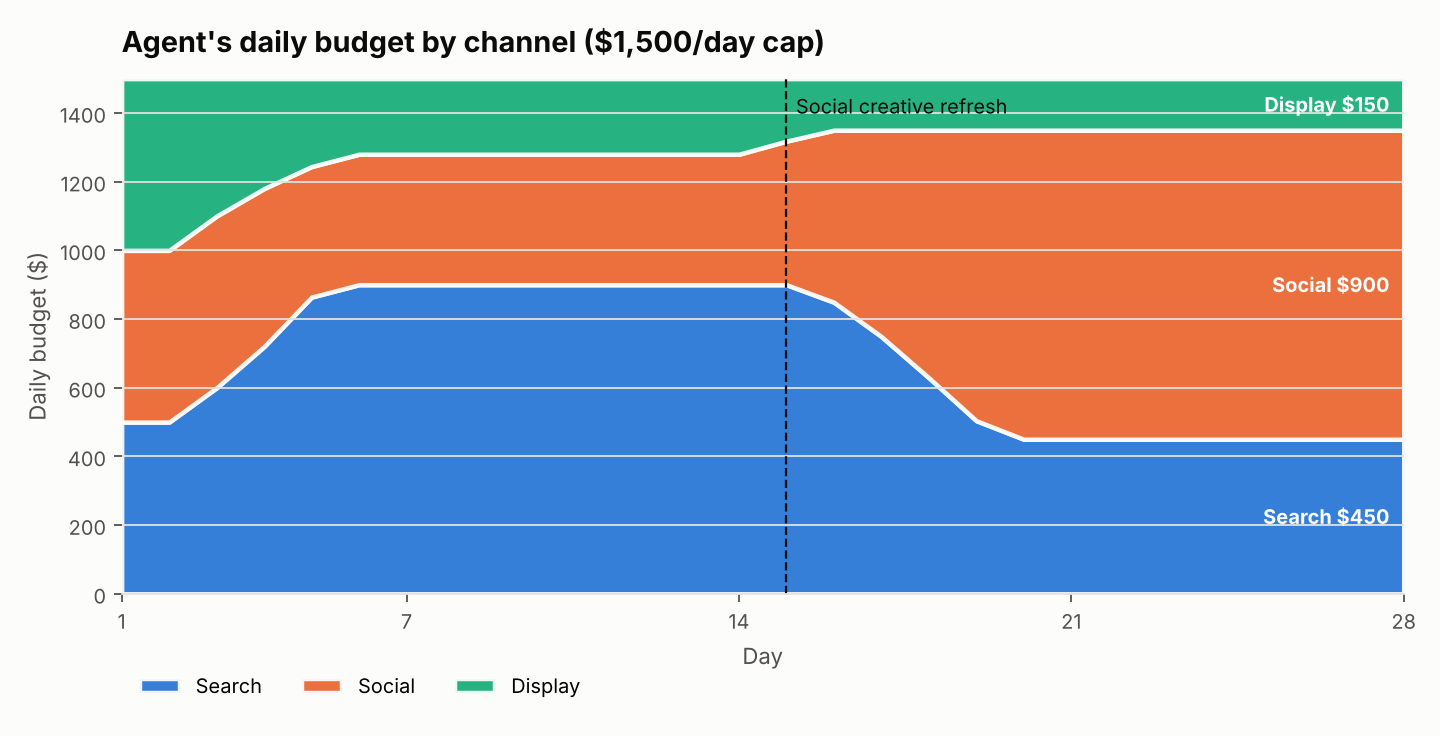

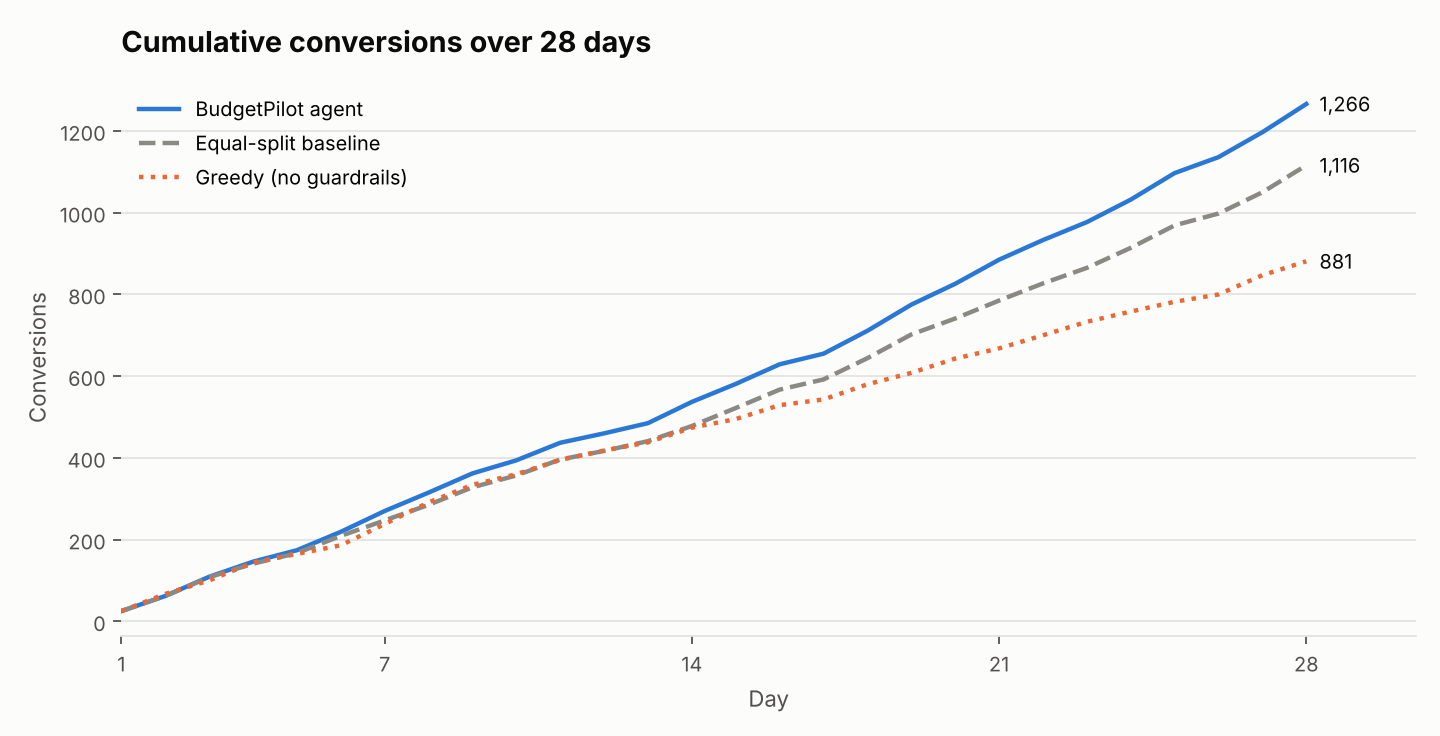

In [11]:
plot_budget_allocation(log, "outputs/budget_allocation.png", refresh_day=15)
plot_cumulative(results, "outputs/cumulative_conversions.png")
display(Image("outputs/budget_allocation.png"))
display(Image("outputs/cumulative_conversions.png"))

In [12]:
# Is the win just luck? Re-run with 100 different noise seeds, and vary the diminishing-returns assumption
robust = robustness(data, config, elasticity=0.35, n_seeds=100)
print(json.dumps(robust, indent=2))
pd.DataFrame(sensitivity(data, config, seed=42))

{
  "seeds": 100,
  "mean_uplift_pct": 11.5,
  "min_uplift_pct": 5.32,
  "max_uplift_pct": 18.01,
  "agent_wins_pct": 100.0
}


,elasticity,agent_conversions,baseline_conversions,uplift_pct
0,0.20,1333,1116,19.44
1,0.35,1266,1116,13.44
2,0.50,1210,1116,8.42


## 6. Results & trade-offs
- **The agent beats the equal split** by about **+13% conversions** at a **~12% lower CPA** with the same $42,000 spend. Across 100 noise seeds the uplift was positive every time (about +5% to +18%).
- **It adapts:** it moved money to Search in days 3–6 (best CPA), held at the 60% cap, then shifted to Social after Social's creative refresh made it the cheapest channel (days 15–20).
- **Guardrails cost a little upside but buy safety:** the ±20%/day limit means it takes ~4–5 days to react, and the 10% floor keeps ~$150/day in Display. But the *greedy, no-guardrail* version put everything into Search on day 2, never saw Social improve, and hit diminishing returns — it finished **below** the baseline.
- **Assumptions:** mock data; results depend on the diminishing-returns strength (uplift ≈ +8% to +19% for elasticity 0.5 to 0.2); budget is moved at the channel level only (no bids, creative or targeting).

In [13]:
# Guardrail + tool tests
import subprocess, sys
print(subprocess.run([sys.executable, "tests/test_agent.py"], capture_output=True, text=True).stdout)

PASS  test_csv_has_required_shape
PASS  test_guardrails_hold_every_day
PASS  test_oversized_shift_is_capped
PASS  test_donor_never_goes_below_floor
PASS  test_no_future_data_leaks
PASS  test_privacy_guardrail_rejects_pii
PASS  test_tone_guardrail
  [llm] advisor unavailable (TimeoutError); using rule-based proposal
PASS  test_llm_advice_is_sanitized_and_falls_back

All 8 tests passed.

